# Exploratory Data Analysis (EDA) Project
# Phase 2 — 1D Statistical Analysis

**Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Course:** Exploratory Data Analysis (EDA)  
**Dataset:** Indian Food Dataset

## Objective

The objective of this notebook is to perform one-dimensional (1D) statistical analysis on individual variables of the Indian Food dataset.

The analysis includes measures of central tendency, measures of dispersion, quartiles and percentiles, skewness, kurtosis, and outlier detection. Appropriate visualizations will also be used to understand the distribution of individual numerical variables.

PHASE 2 - 1D STATISTICAL ANALYSIS

Dataset loaded successfully.
Rows    : 255
Columns : 20

NUMERICAL VARIABLES USED
['prep_time', 'cook_time', 'total_time']

1. MEASURES OF CENTRAL TENDENCY


,Mean,Median,Mode
prep_time,31.105882,10.0,10
cook_time,34.529412,30.0,30
total_time,65.635294,50.0,50



2. MEASURES OF DISPERSION


,Variance,Standard Deviation,Minimum,Maximum,Range
prep_time,5264.142288,72.554409,-1,500,501
cook_time,2329.572950,48.265650,-1,720,721
total_time,8603.051505,92.752636,-2,730,732



3. QUARTILES AND PERCENTILES


,prep_time,cook_time,total_time
10th Percentile,-1.0,-1.0,-2.0
25th Percentile (Q1),10.0,20.0,30.0
50th Percentile (Median),10.0,30.0,50.0
75th Percentile (Q3),20.0,40.0,60.0
90th Percentile,45.0,60.0,100.0


... (2 outputs left out)


5. SKEWNESS AND KURTOSIS


,Skewness,Kurtosis
prep_time,4.636301,23.081615
cook_time,11.433430,161.176069
total_time,4.327346,21.708282



6. OUTLIER DETECTION USING IQR METHOD


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers
0,prep_time,10.0,20.0,10.0,-5.0,35.0,30
1,cook_time,20.0,40.0,20.0,-10.0,70.0,12
2,total_time,30.0,60.0,30.0,-15.0,105.0,22


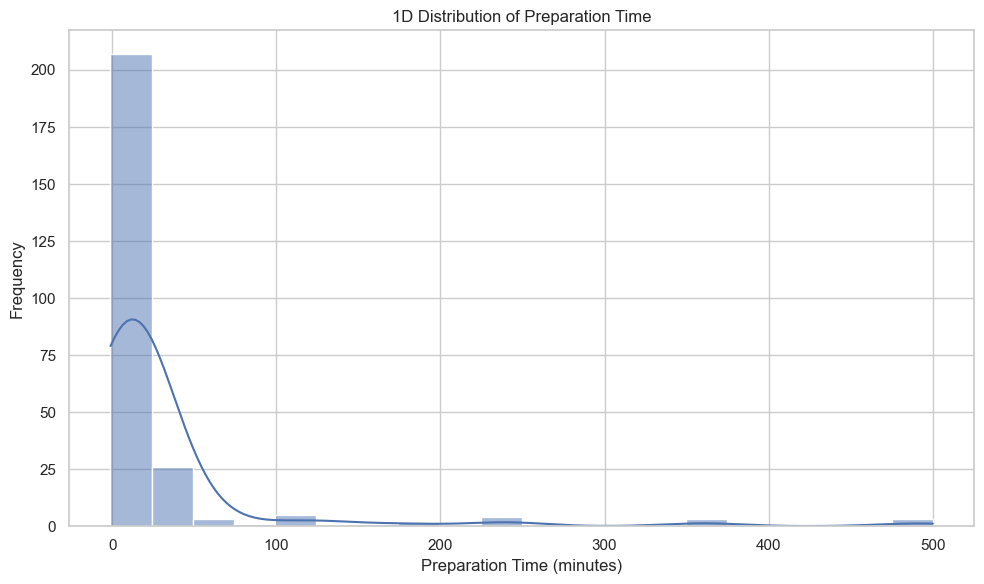

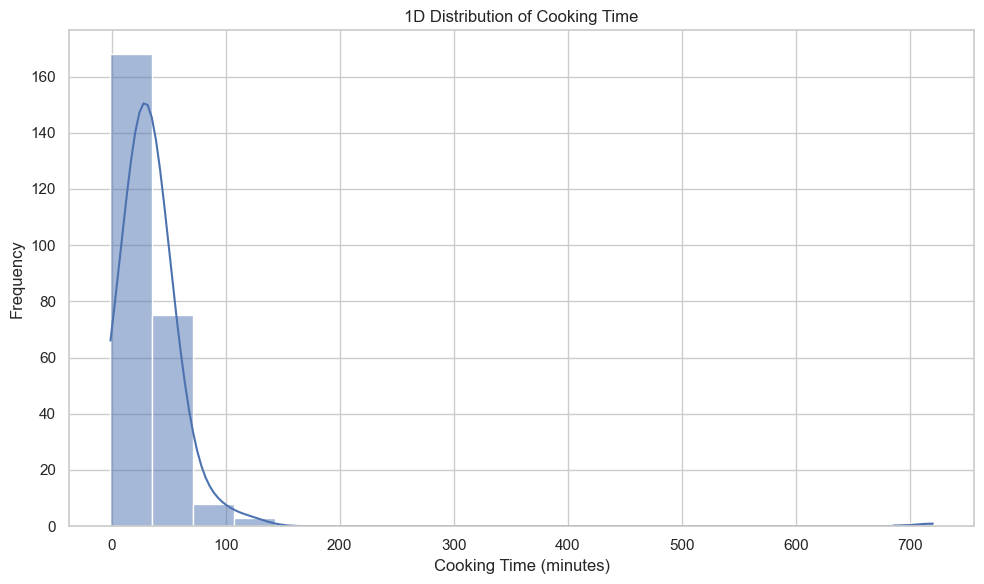

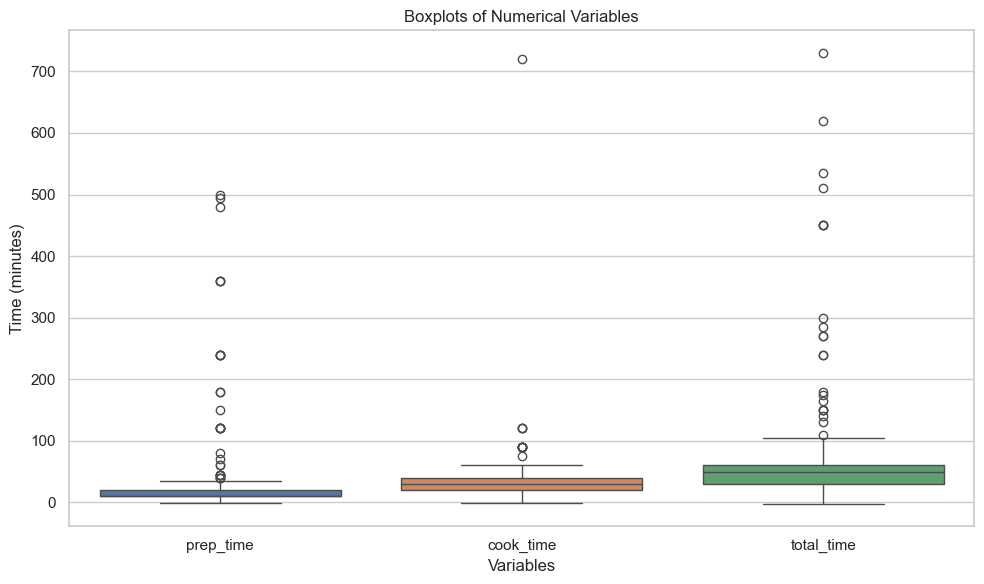

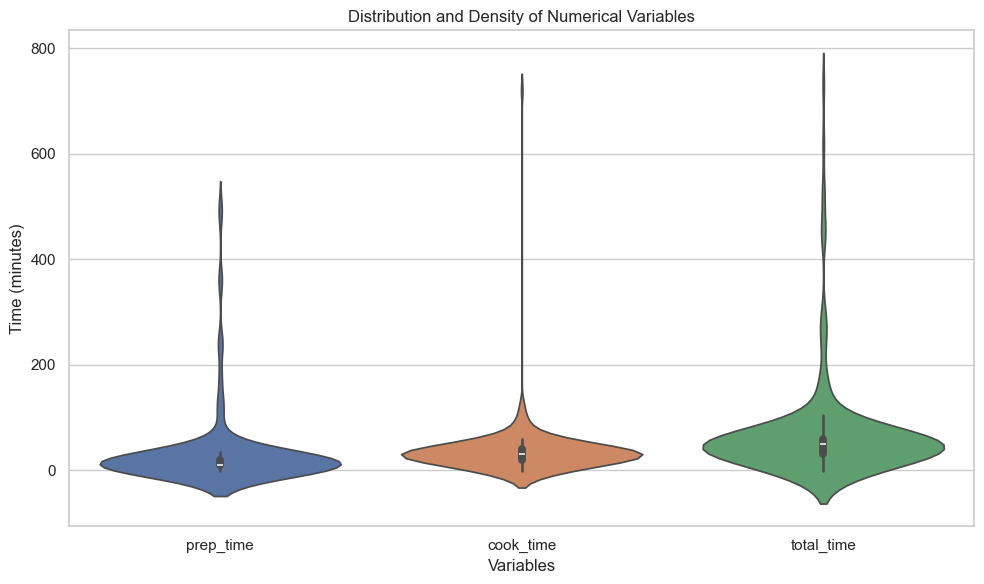


FINAL 1D STATISTICAL SUMMARY


,Mean,Median,Std Dev,Skewness,Kurtosis
prep_time,31.105882,10.0,72.554409,4.636301,23.081615
cook_time,34.529412,30.0,48.265650,11.433430,161.176069
total_time,65.635294,50.0,92.752636,4.327346,21.708282



1D STATISTICAL ANALYSIS COMPLETED


In [1]:
# ============================================================
# PHASE 2 - 1D STATISTICAL ANALYSIS
# Name        : ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset     : Indian Food Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Load the transformed dataset
# ------------------------------------------------------------

file_path = "indian_food_transformed.csv"

df = pd.read_csv(file_path)

print("=" * 75)
print("PHASE 2 - 1D STATISTICAL ANALYSIS")
print("=" * 75)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

sns.set_theme(style="whitegrid")


# ------------------------------------------------------------
# 2. Select numerical variables
# ------------------------------------------------------------

numerical_columns = [
    "prep_time",
    "cook_time",
    "total_time"
]

print("\nNUMERICAL VARIABLES USED")
print("=" * 75)
print(numerical_columns)


# ------------------------------------------------------------
# 3. Measures of Central Tendency
# ------------------------------------------------------------

print("\n1. MEASURES OF CENTRAL TENDENCY")
print("=" * 75)

central_tendency = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": [
        df[column].mode().iloc[0]
        if not df[column].mode().empty
        else np.nan
        for column in numerical_columns
    ]
})

display(central_tendency)


# ------------------------------------------------------------
# 4. Measures of Dispersion
# ------------------------------------------------------------

print("\n2. MEASURES OF DISPERSION")
print("=" * 75)

dispersion = pd.DataFrame({
    "Variance": df[numerical_columns].var(),
    "Standard Deviation": df[numerical_columns].std(),
    "Minimum": df[numerical_columns].min(),
    "Maximum": df[numerical_columns].max(),
    "Range": (
        df[numerical_columns].max()
        - df[numerical_columns].min()
    )
})

display(dispersion)


# ------------------------------------------------------------
# 5. Quartiles and Percentiles
# ------------------------------------------------------------

print("\n3. QUARTILES AND PERCENTILES")
print("=" * 75)

quartile_table = df[numerical_columns].quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90]
)

quartile_table.index = [
    "10th Percentile",
    "25th Percentile (Q1)",
    "50th Percentile (Median)",
    "75th Percentile (Q3)",
    "90th Percentile"
]

display(quartile_table)


# ------------------------------------------------------------
# 6. Interquartile Range
# ------------------------------------------------------------

print("\n4. INTERQUARTILE RANGE (IQR)")
print("=" * 75)

iqr = (
    df[numerical_columns].quantile(0.75)
    - df[numerical_columns].quantile(0.25)
)

iqr_table = pd.DataFrame({
    "Q1": df[numerical_columns].quantile(0.25),
    "Q3": df[numerical_columns].quantile(0.75),
    "IQR": iqr
})

display(iqr_table)


# ------------------------------------------------------------
# 7. Skewness and Kurtosis
# ------------------------------------------------------------

print("\n5. SKEWNESS AND KURTOSIS")
print("=" * 75)

distribution_shape = pd.DataFrame({
    "Skewness": df[numerical_columns].skew(),
    "Kurtosis": df[numerical_columns].kurt()
})

display(distribution_shape)


# ------------------------------------------------------------
# 8. Outlier Detection using IQR Method
# ------------------------------------------------------------

print("\n6. OUTLIER DETECTION USING IQR METHOD")
print("=" * 75)

outlier_summary = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound)
        | (df[column] > upper_bound)
    ]

    outlier_summary.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": len(outliers)
    })

outlier_table = pd.DataFrame(outlier_summary)

display(outlier_table)


# ------------------------------------------------------------
# 9. Visualization 1 - Distribution of Preparation Time
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="prep_time",
    kde=True,
    bins=20
)

plt.title("1D Distribution of Preparation Time")
plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Visualization 2 - Distribution of Cooking Time
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="cook_time",
    kde=True,
    bins=20
)

plt.title("1D Distribution of Cooking Time")
plt.xlabel("Cooking Time (minutes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Visualization 3 - Boxplots of Numerical Variables
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df[numerical_columns]
)

plt.title("Boxplots of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Time (minutes)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Visualization 4 - Violin Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df[numerical_columns]
)

plt.title("Distribution and Density of Numerical Variables")
plt.xlabel("Variables")
plt.ylabel("Time (minutes)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Summary
# ------------------------------------------------------------

print("\nFINAL 1D STATISTICAL SUMMARY")
print("=" * 75)

summary = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Std Dev": df[numerical_columns].std(),
    "Skewness": df[numerical_columns].skew(),
    "Kurtosis": df[numerical_columns].kurt()
})

display(summary)

print("\n" + "=" * 75)
print("1D STATISTICAL ANALYSIS COMPLETED")
print("=" * 75)

## Conclusion

One-dimensional statistical analysis was successfully performed on the numerical variables of the Indian Food dataset.

Measures of central tendency and dispersion were calculated to understand the typical values and variability of preparation time, cooking time, and total time. Quartiles, percentiles, and interquartile ranges were calculated to describe the distributions in greater detail.

Skewness and kurtosis were used to examine the shape of the distributions, while the IQR method was applied to identify potential outliers.

Histograms, boxplots, and violin plots provided visual representations of the distributions and spread of the individual numerical variables.

The results provide a detailed statistical understanding of individual variables and form the basis for the 2D statistical analysis in the next stage.